# Single-subject TFA

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/htfa/blob/main/docs/tutorials/02_tfa_single_subject.ipynb)

`htfa.TFA` fits one subject: `X ≈ F(R; centers, widths) W`, where `X` is `(V, T)` data, `R` the `(V, D)` voxel coordinates, `F` a `(V, K)` matrix of radial basis factors (Gaussians with a center and a width `w = 2 sigma^2`) and `W` the `(K, T)` weights. This tutorial uses the estimator directly, rather than `htfa.fit`, to look at its options: the initialization, convergence, standardization, subsampling and an explicit starting point.

The data are 2D synthetic data (a 20 x 20 grid, 4 factors, 40 time points), so the truth is known.

In [2]:
# Install htfa if it is missing (for example on Colab); other packages
# install themselves the first time they are needed.
try:
    import htfa  # noqa: F401
except ImportError:
    %pip install -q htfa

In [3]:
import time
import warnings

import numpy as np

import htfa
from htfa.synthetic import match_factors
from htfa.tfa import standardize_data

plt = htfa.require("matplotlib.pyplot")

K = 4
X, R, truth = htfa.make_tfa_data((20, 20), n_samples=40, K=K, noise=0.1, random_state=0)
print("X:", X.shape, "R:", R.shape)
print("true centers:\n", np.round(truth["centers"], 1))
print("true widths:", np.round(truth["widths"], 1))


def errors(model):
    """Matched center error (grid units) and relative width error."""
    perm = match_factors(truth["centers"], model.centers_)
    c = np.linalg.norm(model.centers_[perm] - truth["centers"], axis=1)
    w = np.abs(model.widths_[perm] - truth["widths"]) / truth["widths"]
    return c, w

X: (400, 40) R: (400, 2)
true centers:
 [[14.3 15.8]
 [11.1 13. ]
 [10.2 16.1]
 [14.3  1.9]]
true widths: [7.  4.2 2.8 2.7]


## 1. A first fit

The data are on the generating model's scale, so `standardize=False` preserves the spatial profiles whose parameters we want to recover. The constructor stores the options; `fit(X, coords)` returns the estimator, with fitted attributes that end in an underscore.

In [4]:
t0 = time.perf_counter()
tfa = htfa.TFA(K=K, standardize=False, random_state=0).fit(X, R)
print(f"fit time: {time.perf_counter() - t0:.1f} s")
c, w = errors(tfa)
print("center error per factor:", np.round(c, 2))
print("relative width error per factor:", np.round(w, 3))
print(
    "centers_",
    tfa.centers_.shape,
    "widths_",
    tfa.widths_.shape,
    "weights_",
    tfa.weights_.shape,
)
print("winning init_:", tfa.init_, "| n_iter_:", tfa.n_iter_, "| engine_:", tfa.engine_)
print("converged_:", tfa.converged_, "| converged_reason_:", tfa.converged_reason_)
print(f"cost_: {tfa.cost_:.3f}")
r = np.corrcoef(tfa.reconstruct().ravel(), X.ravel())[0, 1]
print(f"correlation of reconstruction with data: {r:.4f}")

fit time: 0.1 s
center error per factor: [0.01 0.01 0.03 0.02]
relative width error per factor: [0.023 0.023 0.039 0.049]
centers_ (4, 2) widths_ (4,) weights_ (4, 40)
winning init_: ncorr | n_iter_: 2 | engine_: numpy
converged_: True | converged_reason_: threshold
cost_: 544.492
correlation of reconstruction with data: 0.9295


## 2. Initialization

`init` chooses the starting centers and widths. Each option is a K-means++ draw on the voxel coordinates:

- `'kmeans'`: unweighted, as in BrainIAK;
- `'power'`: voxels weighted by their signal power;
- `'ncorr'`: voxels weighted by the squared mean correlation with their nearest spatial neighbors;
- `'auto'` (default): all of these. Each candidate is fitted and the one with the lowest full-data objective wins. `init_objectives_` holds the objective of every candidate.

The loop below fits each option separately, then `'auto'`. The last lines of the next cell fit `'auto'` on per-voxel z-scored data (`standardize='auto'`) and print which candidates run: `'ncorr'` and `'kmeans'`, without `'power'`, whereas all three run with `standardize=False`.

In [5]:
fits = {}
for init in ["kmeans", "power", "ncorr", "auto"]:
    t0 = time.perf_counter()
    m = htfa.TFA(K=K, init=init, standardize=False, random_state=0).fit(X, R)
    fits[init] = m
    c, w = errors(m)
    print(
        f"init={init:6s} winner={m.init_:6s} n_iter={m.n_iter_:3d} "
        f"reason={m.converged_reason_:9s} cost={m.cost_:9.3f} "
        f"max center err={c.max():.2f} max width err={w.max():.3f} "
        f"({time.perf_counter() - t0:.1f} s)"
    )
print("\ninit_objectives_ of the 'auto' fit:")
for name, value in fits["auto"].init_objectives_.items():
    print(f"  {name:6s} {value:.3f}")

# On per-voxel z-scored data every voxel has the same power, so 'power' is skipped.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    z = htfa.TFA(K=K, init="auto", standardize="auto", random_state=0).fit(X, R)
print("\ncandidates run with standardize='auto':", list(z.init_objectives_))
print("candidates run with standardize=False :", list(fits["auto"].init_objectives_))

init=kmeans winner=kmeans n_iter=  2 reason=threshold cost=  544.492 max center err=0.03 max width err=0.049 (0.0 s)
init=power  winner=power  n_iter=  2 reason=threshold cost=  544.492 max center err=0.03 max width err=0.049 (0.0 s)
init=ncorr  winner=ncorr  n_iter=  2 reason=threshold cost=  544.492 max center err=0.03 max width err=0.049 (0.0 s)


init=auto   winner=ncorr  n_iter=  2 reason=threshold cost=  544.492 max center err=0.03 max width err=0.049 (0.0 s)

init_objectives_ of the 'auto' fit:
  ncorr  544.492
  power  544.492
  kmeans 544.492

candidates run with standardize='auto': ['ncorr', 'kmeans']
candidates run with standardize=False : ['ncorr', 'power', 'kmeans']


The table compares each initialization's objective and parameter recovery. `init='auto'` selects the candidate with the smallest objective; its `init_objectives_` records all candidates. Small objective differences can occur between starts that recover similar factors.

## 3. Convergence

The default variable-projection solver updates the centers and widths while solving ridge weights at each spatial evaluation. The weights are also fitted on all observations at each outer iteration; spatial subsampling can limit the nonlinear subproblem. The fit stops when the scaled change between iterations falls below `threshold` (`converged_reason_ == 'threshold'`) or after `max_iter` iterations (`'max_iter'`). Reaching `max_iter` raises a `ConvergenceWarning`. `max_iter=0` evaluates the starting point without iteration.

In [6]:
for kwargs in [
    dict(max_iter=100, threshold=1e-3),
    dict(max_iter=100, threshold=1e-1),
    dict(max_iter=2, threshold=1e-3),
    dict(max_iter=0, threshold=1e-3),
]:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        m = htfa.TFA(
            K=K, init="ncorr", standardize=False, random_state=0, **kwargs
        ).fit(X, R)
    c, w = errors(m)
    print(
        f"{kwargs}: n_iter={m.n_iter_}, converged_={m.converged_}, "
        f"reason={m.converged_reason_}, cost={m.cost_:.3f}, "
        f"max center err={c.max():.2f}, "
        f"warnings={[x.category.__name__ for x in caught]}"
    )

{'max_iter': 100, 'threshold': 0.001}: n_iter=2, converged_=True, reason=threshold, cost=544.492, max center err=0.03, warnings=[]
{'max_iter': 100, 'threshold': 0.1}: n_iter=2, converged_=True, reason=threshold, cost=544.492, max center err=0.03, warnings=[]
{'max_iter': 2, 'threshold': 0.001}: n_iter=2, converged_=True, reason=threshold, cost=544.492, max center err=0.03, warnings=[]
{'max_iter': 0, 'threshold': 0.001}: n_iter=0, converged_=False, reason=max_iter, cost=1274.903, max center err=1.35, warnings=[]


The printed rows show the tradeoff between stopping tolerance, iterations, and objective. A larger threshold permits earlier stopping. The two-iteration fit illustrates the iteration limit and its `ConvergenceWarning`; `max_iter=0` reports the initial objective and parameter errors.

## 4. Standardization

Real data have an arbitrary intensity offset and scale at every voxel, and the TFA model has no intercept. With `standardize='auto'` (the default) each voxel is z-scored over time whenever `T > 1`; `False` fits the raw values. Below, the synthetic data get a different offset and scale at every voxel (`X_raw`), as fMRI intensity differs between voxels, and each version is fitted with both settings.

Z-scoring gives every voxel unit variance, including voxels that no factor reaches, so the factors fitted to standardized data describe the standardized data, not the generating `F W`. The width errors below are measured against the generating widths and need not reach zero.

In [7]:
rng = np.random.default_rng(1)
scale = rng.uniform(5, 50, size=(X.shape[0], 1))
offset = rng.uniform(500, 1500, size=(X.shape[0], 1))
X_raw = X * scale + offset
print(
    "raw data mean / std over all entries:",
    round(X_raw.mean(), 1),
    round(X_raw.std(), 1),
)


diff = np.abs(standardize_data(X_raw, "auto") - standardize_data(X, "auto")).max()
print(f"max |standardized(X_raw) - standardized(X)|: {diff:.1e}")

for name, data in [("X", X), ("X_raw", X_raw)]:
    for std in [False, "auto"]:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = htfa.TFA(K=K, standardize=std, random_state=0).fit(data, R)
        c, w = errors(m)
        print(
            f"{name:5s} standardize={std!r:7}: reason={m.converged_reason_:9s} "
            f"center err={np.round(c, 2)} width err={np.round(w, 2)}"
        )

raw data mean / std over all entries: 1019.2 291.1
max |standardized(X_raw) - standardized(X)|: 5.6e-13


X     standardize=False  : reason=threshold center err=[0.01 0.01 0.03 0.02] width err=[0.02 0.02 0.04 0.05]


X     standardize='auto' : reason=threshold center err=[0.42 0.53 0.63 0.04] width err=[2.11 1.18 1.24 2.12]
X_raw standardize=False  : reason=threshold center err=[7.79 3.78 6.6  8.94] width err=[16.19 27.56 41.5  43.57]


X_raw standardize='auto' : reason=threshold center err=[0.42 0.53 0.63 0.04] width err=[2.11 1.18 1.24 2.12]


Per-voxel z-scoring removes a constant offset and positive scale at each voxel, so `X` and `X_raw` standardize to the same array up to floating-point error. Without standardization, the fit must also represent intensity differences across voxels; compare its errors with the standardized fit. The standardized factors need not match the generating widths because standardization changes the spatial profile of the signal.

`htfa.tfa.standardize_data` applies the same transform to an array, and `reconstruct()` returns values in the fitted space.

## 5. Subsampling

For large data, each iteration can update the centers and widths from a random subset of voxels and time points: `voxel_ratio` and `tr_ratio` give fractions, `max_voxels` and `max_trs` give caps (the data are never oversampled). The weights are always fitted on the full data. A new subset is drawn every iteration, so the change between iterations does not settle as it does with all the data. The fit therefore also evaluates the objective after every iteration, on one fixed random evaluation subsample (`max(2 Vs, 6000)` voxels, all of them here, and all time points unless `max_trs` caps them), and stops (`'objective'`) when its lowest value so far has fallen by less than a relative 1e-4 per iteration over the last 3 iterations, after at least 5 iterations; or on a `'plateau'` when the change has not reached a new minimum for 5 consecutive iterations. It then returns the iterate with the lowest objective (`objective_history_` holds the values), not the last one; `cost_` is the full-data objective there.

In [8]:
for kwargs in [
    dict(),
    dict(voxel_ratio=0.5),
    dict(voxel_ratio=0.5, tr_ratio=0.5),
    dict(max_voxels=100, max_trs=20),
]:
    t0 = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = htfa.TFA(
            K=K, init="ncorr", standardize=False, random_state=0, **kwargs
        ).fit(X, R)
    c, w = errors(m)
    print(
        f"{str(kwargs):38s} n_iter={m.n_iter_:3d} reason={m.converged_reason_:9s} "
        f"max center err={c.max():.2f} max width err={w.max():.3f} "
        f"({time.perf_counter() - t0:.1f} s)"
    )

{}                                     n_iter=  2 reason=threshold max center err=0.03 max width err=0.049 (0.0 s)
{'voxel_ratio': 0.5}                   n_iter=  5 reason=objective max center err=0.06 max width err=0.115 (0.0 s)


{'voxel_ratio': 0.5, 'tr_ratio': 0.5}  n_iter=  6 reason=objective max center err=0.04 max width err=0.130 (0.0 s)


{'max_voxels': 100, 'max_trs': 20}     n_iter=  8 reason=objective max center err=0.15 max width err=0.080 (0.0 s)


The printed stopping reasons and parameter errors compare subsampled fits with the full-data fit. The weights `weights_` are fitted on all data in every case.

## 6. An explicit starting point

`fit(X, R, start=(centers, widths))` skips the initialization. The start is used as given; here it is the true centers and widths, then the true values displaced by a few grid units. `max_iter=0` reports how good the start is before any iteration.

In [9]:
rng = np.random.default_rng(2)
true_start = (truth["centers"], truth["widths"])
bad_start = (
    truth["centers"] + rng.normal(0, 3, truth["centers"].shape),
    truth["widths"] * 1.5,
)

for name, start in [("true values", true_start), ("displaced values", bad_start)]:
    m0 = htfa.TFA(K=K, max_iter=0, standardize=False, random_state=0).fit(
        X, R, start=start
    )
    m = htfa.TFA(K=K, standardize=False, random_state=0).fit(X, R, start=start)
    c0, _ = errors(m0)
    c, w = errors(m)
    print(
        f"{name:17s}: start center err max {c0.max():.2f}, cost {m0.cost_:.3f} -> "
        f"after fit: n_iter={m.n_iter_}, max center err {c.max():.2f}, "
        f"max width err {w.max():.3f}, cost {m.cost_:.3f}"
    )

true values      : start center err max 0.00, cost 544.365 -> after fit: n_iter=2, max center err 0.03, max width err 0.049, cost 544.492
displaced values : start center err max 7.43, cost 2790.939 -> after fit: n_iter=2, max center err 11.48, max width err 0.747, cost 990.565


Compare the parameter errors and objectives from the true and displaced starting points. Nonlinear fitting can reach different local solutions, which is why `init='auto'` compares several starts.

## 7. Looking at the factors

`TFA.factors()` returns the `(V, K)` factor matrix at the training coordinates (or at any coordinates passed in). For 2D data the factors can be shown as images.

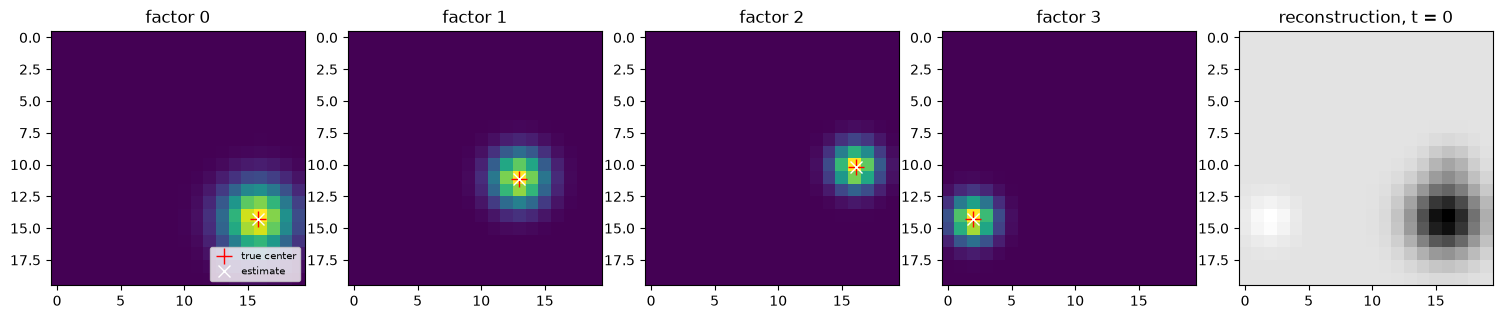

In [10]:
F = tfa.factors()
c, _ = errors(tfa)
perm = match_factors(truth["centers"], tfa.centers_)
fig, axes = plt.subplots(1, K + 1, figsize=(3 * (K + 1), 3))
for k, ax in enumerate(axes[:K]):
    ax.imshow(F[:, perm[k]].reshape(20, 20), cmap="viridis")
    ax.plot(
        truth["centers"][k, 1], truth["centers"][k, 0], "r+", ms=12, label="true center"
    )
    ax.plot(
        tfa.centers_[perm[k], 1], tfa.centers_[perm[k], 0], "wx", ms=8, label="estimate"
    )
    ax.set_title(f"factor {k}")
axes[0].legend(loc="lower right", fontsize=7)
axes[K].imshow(tfa.reconstruct()[:, 0].reshape(20, 20), cmap="gray")
axes[K].set_title("reconstruction, t = 0")
fig.tight_layout()
plt.show()